In [44]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
RANDOM_STATE = 42
FILE_PATH = "tuberculosis_indicators_mng.csv"
data = pd.read_csv(FILE_PATH)
print("Original dataset shape:", data.shape)
display(data.head(10))

Original dataset shape: (375, 17)


,GHO (CODE),GHO (DISPLAY),GHO (URL),YEAR (DISPLAY),STARTYEAR,ENDYEAR,REGION (CODE),REGION (DISPLAY),COUNTRY (CODE),COUNTRY (DISPLAY),DIMENSION (TYPE),DIMENSION (CODE),DIMENSION (NAME),Numeric,Value,Low,High
0,TB_c_ret_tsr,Treatment success rate: previously treated TB ...,https://www.who.int/data/gho/data/indicators/i...,1999,1999,1999,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,81.00,81,NaN,NaN
1,TB_c_dst_rlt_ret_pct,Previously treated cases tested for RR-/MDR-TB...,https://www.who.int/data/gho/data/indicators/i...,2016,2016,2016,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,88.00,88,NaN,NaN
2,TB_e_inc_tbhiv_num,"Number of incident tuberculosis cases, (HIV-p...",https://www.who.int/data/gho/data/indicators/i...,2006,2006,2006,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,33.00,33 [9-74],9.00,74.0
3,TB_e_inc_rr_num,Estimated number of MDR/RR-TB incident cases,https://www.who.int/data/gho/data/indicators/i...,2017,2017,2017,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,790.00,790 [320-1300],320.00,1300.0
4,TB_rr_mdr,Confirmed cases of RR-/MDR-TB,https://www.who.int/data/gho/data/indicators/i...,2020,2020,2020,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,179.00,179,NaN,NaN
5,TB_rr_mdr,Confirmed cases of RR-/MDR-TB,https://www.who.int/data/gho/data/indicators/i...,2022,2022,2022,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,161.00,161,NaN,NaN
6,TB_c_dst_rlt_new_pct,New cases tested for RR-/MDR-TB (%),https://www.who.int/data/gho/data/indicators/i...,2019,2019,2019,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,83.00,83,NaN,NaN
7,TB_rr_mdr,Confirmed cases of RR-/MDR-TB,https://www.who.int/data/gho/data/indicators/i...,2017,2017,2017,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,220.00,220,NaN,NaN
8,TB_hivtest_pct,TB patients with known HIV status (%),https://www.who.int/data/gho/data/indicators/i...,2013,2013,2013,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,77.00,77,NaN,NaN
9,TB_e_inc_tbhiv_100k,Incidence of tuberculosis (per 100 000 populat...,https://www.who.int/data/gho/data/indicators/i...,2000,2000,2000,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,0.31,0.31 [0.08-0.7],0.08,0.7


In [4]:
data = pd.read_csv("tuberculosis_indicators_mng.csv")
data.head()

,GHO (CODE),GHO (DISPLAY),GHO (URL),YEAR (DISPLAY),STARTYEAR,ENDYEAR,REGION (CODE),REGION (DISPLAY),COUNTRY (CODE),COUNTRY (DISPLAY),DIMENSION (TYPE),DIMENSION (CODE),DIMENSION (NAME),Numeric,Value,Low,High
0,TB_c_ret_tsr,Treatment success rate: previously treated TB ...,https://www.who.int/data/gho/data/indicators/i...,1999,1999,1999,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,81.0,81,NaN,NaN
1,TB_c_dst_rlt_ret_pct,Previously treated cases tested for RR-/MDR-TB...,https://www.who.int/data/gho/data/indicators/i...,2016,2016,2016,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,88.0,88,NaN,NaN
2,TB_e_inc_tbhiv_num,"Number of incident tuberculosis cases, (HIV-p...",https://www.who.int/data/gho/data/indicators/i...,2006,2006,2006,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,33.0,33 [9-74],9.0,74.0
3,TB_e_inc_rr_num,Estimated number of MDR/RR-TB incident cases,https://www.who.int/data/gho/data/indicators/i...,2017,2017,2017,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,790.0,790 [320-1300],320.0,1300.0
4,TB_rr_mdr,Confirmed cases of RR-/MDR-TB,https://www.who.int/data/gho/data/indicators/i...,2020,2020,2020,WPR,Western Pacific,MNG,Mongolia,NaN,NaN,NaN,179.0,179,NaN,NaN


In [6]:
print("Rows and columns:", data.shape)
print("\\nColumn data types:")
display(data.dtypes.to_frame("Data type"))
print("\\nMissing values:")
display(data.isnull().sum().sort_values(ascending = False).to_frame("Missing values"))
print("\\nNumber of unique indicators:", data["GHO (CODE)"].nunique())
print("Year range:", data["YEAR (DISPLAY)"].min(), "-", data["YEAR (DISPLAY)"].max())
print(data["GHO (DISPLAY)"].value_counts().to_frame("Observations"))

Rows and columns: (375, 17)
\nColumn data types:


,Data type
GHO (CODE),object
GHO (DISPLAY),object
GHO (URL),object
YEAR (DISPLAY),int64
STARTYEAR,int64
ENDYEAR,int64
REGION (CODE),object
REGION (DISPLAY),object
COUNTRY (CODE),object
COUNTRY (DISPLAY),object


\nMissing values:


,Missing values
DIMENSION (NAME),375
DIMENSION (CODE),375
DIMENSION (TYPE),375
High,240
Low,240
COUNTRY (DISPLAY),0
Value,0
Numeric,0
GHO (CODE),0
GHO (DISPLAY),0


\nNumber of unique indicators: 19
Year range: 1995 - 2024
                                                    Observations
GHO (DISPLAY)                                                   
Treatment success rate: previously treated TB c...            29
Treatment success rate: new TB cases                          29
Tuberculosis treatment coverage                               25
Number of incident tuberculosis cases,  (HIV-po...            25
Tuberculosis - new and relapse cases                          25
Incidence of tuberculosis (per 100 000 populati...            25
Number of incident tuberculosis cases                         25
Incidence of tuberculosis (per 100 000 populati...            24
TB patients with known HIV status (%)                         22
Confirmed cases of RR-/MDR-TB                                 20
New cases tested for RR-/MDR-TB (%)                           20
Previously treated cases tested for RR-/MDR-TB (%)            20
Tested TB patients HIV-positive 

In [15]:
clean = clean.reset_index(drop = True)

In [18]:
clean = clean.loc[clean["Numeric"].notna()].copy()
clean = clean.reset_index(drop = True)  

In [19]:
clean["indicator_median"] = (
    clean.groupby("GHO (CODE)")["Numeric"].transform("median")
)

In [20]:
print(clean.shape)
display(clean[[
    "GHO (CODE)",
    "Numeric",
    "indicator_median"
]].head(10))

(375, 18)


,GHO (CODE),Numeric,indicator_median
0,TB_c_ret_tsr,81.00,73.000
1,TB_c_dst_rlt_ret_pct,88.00,89.000
2,TB_e_inc_tbhiv_num,33.00,17.000
3,TB_e_inc_rr_num,790.00,840.000
4,TB_rr_mdr,179.00,176.000
5,TB_rr_mdr,161.00,176.000
6,TB_c_dst_rlt_new_pct,83.00,58.000
7,TB_rr_mdr,220.00,176.000
8,TB_hivtest_pct,77.00,77.500
9,TB_e_inc_tbhiv_100k,0.31,0.525


In [26]:
data["Numeric"] = pd.to_numeric(data["Numeric"], errors = "coerce")
clean = data.dropna (
    subset = ["Numeric", "GHO (CODE)", "YEAR (DISPLAY)"]
).copy()
indicator_counts = clean.groupby("GHO (CODE)").size()
display(indicator_counts)
valid_indicators = indicator_counts[indicator_counts >= 2].index
clean = clean[clean["GHO (CODE)"].isin(valid_indicators)].copy()
clean["indicator_median"] = (
    clean.groupby("GHO (CODE)")["Numeric"].transform("median")
)     
clean["Target"] = (
    clean["Numeric"] > clean["indicator_median"]
         ).astype(int)
clean["YEAR (DISPLAY)"] = pd.to_numeric(
    clean["YEAR (DISPLAY)"],errors = "coerce"
         )
clean["Decade"] = (
    (clean["YEAR (DISPLAY)"] // 10) * 10
    ).astype(int).astype(str)
clean = clean.reset_index(drop = True)
print("Cleaned dataset shape:", clean.shape)
display(clean[["GHO (CODE)", "YEAR (DISPLAY)", "Decade", "Target"]].head(10))

GHO (CODE)
MDG_0000000020          25
TB_1                    25
TB_c_dst_rlt_new_pct    20
TB_c_dst_rlt_ret_pct    20
TB_c_mdr_tsr            17
TB_c_mdr_tx             17
TB_c_new_tsr            29
TB_c_newinc             25
TB_c_ret_tsr            29
TB_c_tbhiv_tsr          16
TB_c_xdr_tsr             7
TB_e_inc_num            25
TB_e_inc_num_014         1
TB_e_inc_rr_num         10
TB_e_inc_tbhiv_100k     24
TB_e_inc_tbhiv_num      25
TB_hivtest_pct          22
TB_hivtest_pos_pct      18
TB_rr_mdr               20
dtype: int64

Cleaned dataset shape: (374, 20)


,GHO (CODE),YEAR (DISPLAY),Decade,Target
0,TB_c_ret_tsr,1999,1990,1
1,TB_c_dst_rlt_ret_pct,2016,2010,0
2,TB_e_inc_tbhiv_num,2006,2000,1
3,TB_e_inc_rr_num,2017,2010,0
4,TB_rr_mdr,2020,2020,1
5,TB_rr_mdr,2022,2020,0
6,TB_c_dst_rlt_new_pct,2019,2010,1
7,TB_rr_mdr,2017,2010,1
8,TB_hivtest_pct,2013,2010,0
9,TB_e_inc_tbhiv_100k,2000,2000,0


In [31]:
import matplotlib.pyplot as plt

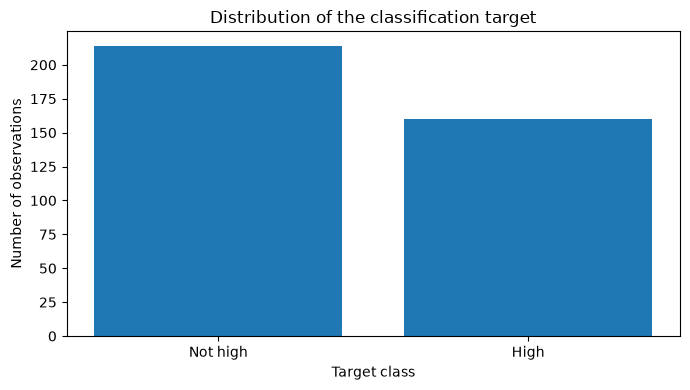

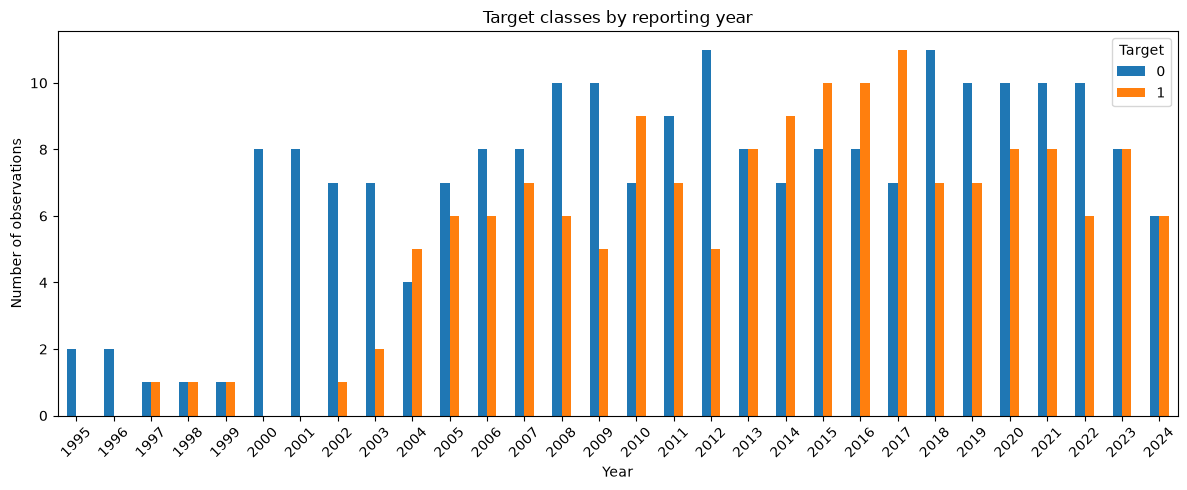

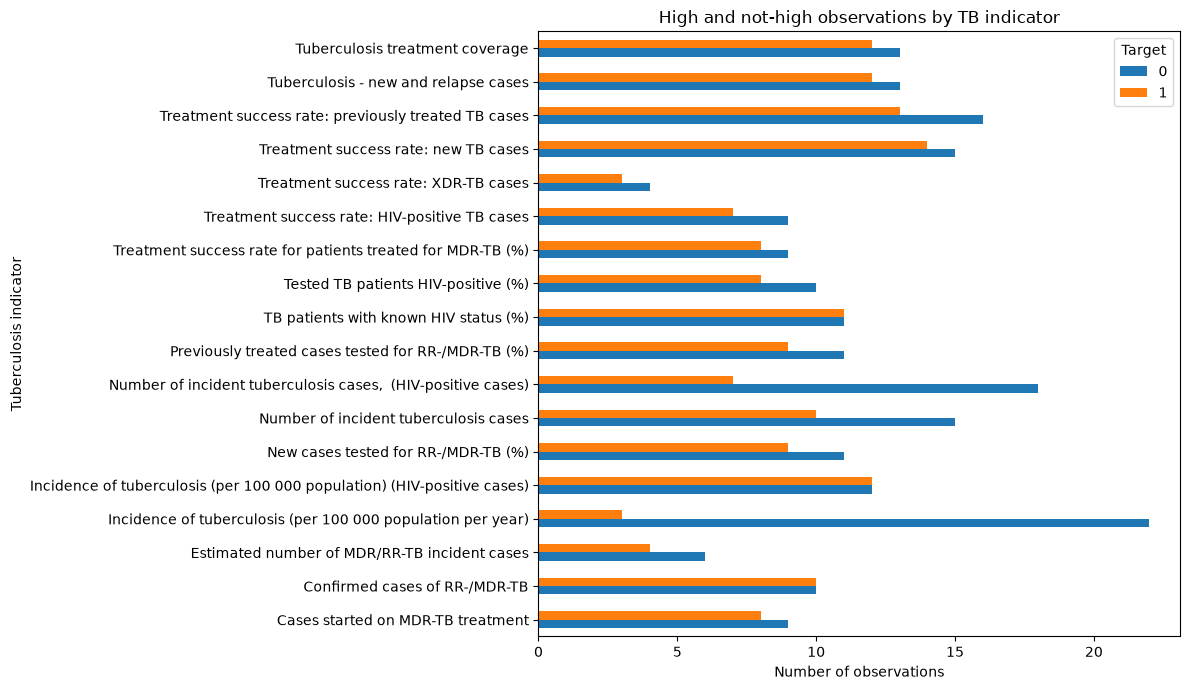

In [33]:
plt.figure(figsize = (7,4))
counts = clean["Target"].value_counts().reindex([0,1],fill_value = 0)
plt.bar(["Not high", "High"], counts.values)
plt.title("Distribution of the classification target")
plt.xlabel("Target class")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()
year_class = clean.groupby(["YEAR (DISPLAY)", "Target"]).size().unstack(fill_value = 0)
year_class.plot(kind = "bar", stacked = False, figsize=(12,5))
plt.title("Target classes by reporting year")
plt.xlabel("Year")
plt.ylabel("Number of observations")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()
indicator_class = clean.groupby(["GHO (DISPLAY)", "Target"]).size().unstack(fill_value = 0)
indicator_class.plot(kind = "barh", stacked = False, figsize=(12,7))
plt.title("High and not-high observations by TB indicator")
plt.xlabel("Number of observations")
plt.ylabel("Tuberculosis indicator")
plt.tight_layout()
plt.show()

In [40]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer

In [52]:
x = clean[["GHO (CODE)", "YEAR (DISPLAY)", "Decade"]].copy()
y = clean["Target"].copy()
categorical_features = ["GHO (CODE)", "Decade"]
numeric_features = ["YEAR (DISPLAY)"]
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown = "ignore"))
])
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])
preprocessor = ColumnTransformer(transformers = [
    ("cat", categorical_preprocessor, categorical_features),
    ("num", numeric_preprocessor, numeric_features),
])
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(class_weight = "balanced"))
])
print("Features used:", x.columns.tolist())
print("Number of observations:", len(x))

Features used: ['GHO (CODE)', 'YEAR (DISPLAY)', 'Decade']
Number of observations: 374


In [53]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators = 200,
        class_weight = "balanced",
        random_state = RANDOM_STATE,
    ))
])
svm_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        class_weight = "balanced"
        ))
])
print("Both models created successfully")

Both models created successfully


In [55]:
split_results = []
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = RANDOM_STATE)
for test_fraction in [0.5, 0.15, 0.25]:
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size = test_fraction, random_state = RANDOM_STATE, stratify = y
    )
for model_name, model in [
    ("Random Forest", rf_pipeline),
    ("Support Vector Machine", svm_pipeline)
]:
    cv_scores = cross_validate(
        model, x_train, y_train, cv = cv,
        scoring = ["accuracy", "precision", "recall", "f1"],
        n_jobs = - 1
    )
    model.fit(x_train, y_train)
    predictions = model.predict(x_test)
    split_results.append({
    "Test size": test_fraction,
    "Training size": test_fraction,
    "Model": model_name,
    "CV accuracy mean": cv_scores["test_accuracy"].mean(),
    "CV accuracy std": cv_scores["test_accuracy"].std(),
    "Test accuracy": accuracy_score(y_test, predictions),
    "Test p[recision": precision_score(y_test, predictions, zero_division = 0),
    "Test recall": recall_score(y_test, predictions, zero_division = 0),
    "Test F1": f1_score(y_test, predictions, zero_division = 0),
    })
split_results_df = pd.DataFrame(split_results)
display(split_results_df.round(3))

,Test size,Training size,Model,CV accuracy mean,CV accuracy std,Test accuracy,Test p[recision,Test recall,Test F1
0,0.25,0.25,Random Forest,0.750,0.041,0.766,0.696,0.8,0.744
1,0.25,0.25,Support Vector Machine,0.654,0.040,0.574,0.500,0.5,0.500


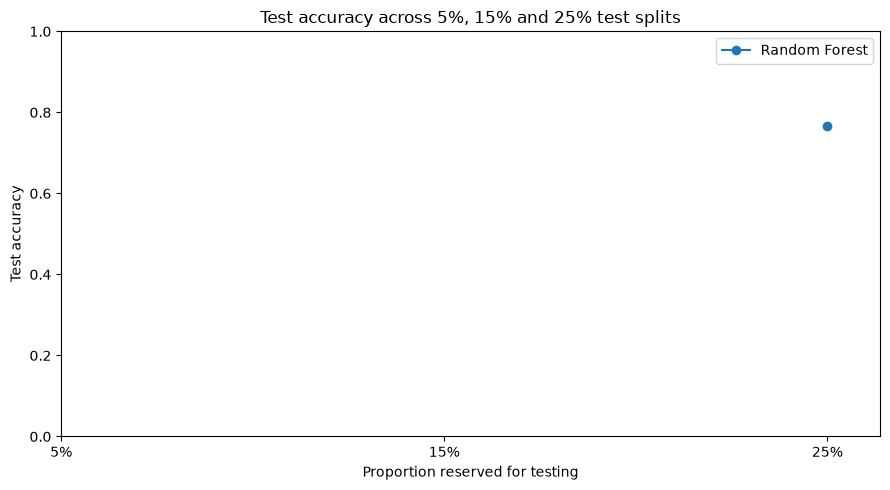

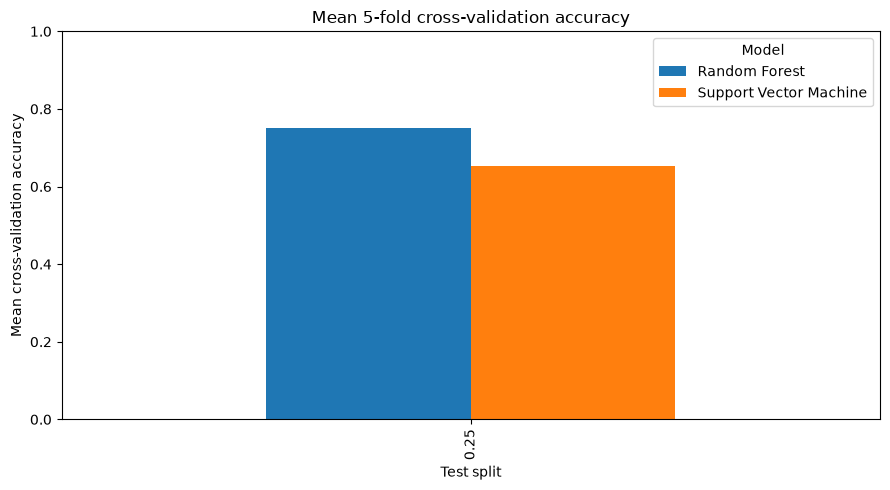

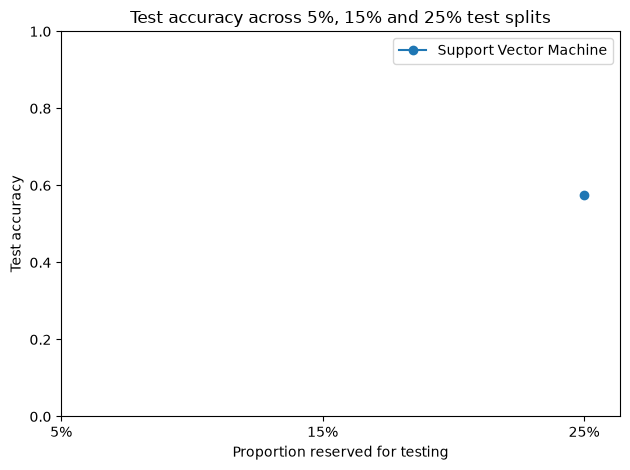

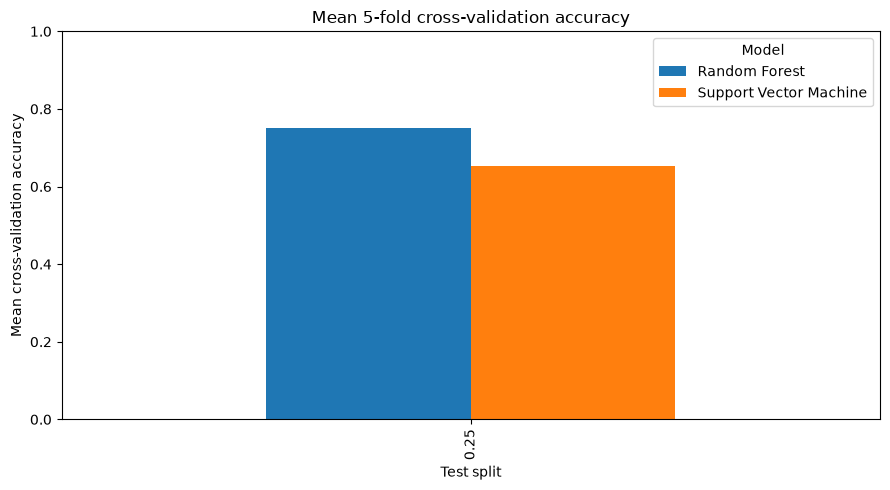

In [57]:
plt.figure(figsize = (9,5))
for model_name, group in split_results_df.groupby("Model"):
    plt.plot(group["Test size"], group["Test accuracy"], marker = "o", label = model_name)
    plt.title("Test accuracy across 5%, 15% and 25% test splits")
    plt.xlabel("Proportion reserved for testing")
    plt.ylabel("Test accuracy")
    plt.xticks([0.05, 0.15, 0.25], ["5%", "15%", "25%"])
    plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()
    plt.show()
    cv_plot = split_results_df.pivot(index = "Test size", columns = "Model", values = "CV accuracy mean")
    cv_plot.plot(kind = "bar", figsize = (9,5))
    plt.title("Mean 5-fold cross-validation accuracy")
    plt.xlabel("Test split")
    plt.ylabel("Mean cross-validation accuracy")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

In [64]:
x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size = 0.25, random_state = RANDOM_STATE, stratify = y
)
rf_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2,4]
}
svm_grid = {
    "classifier__C": [0.01, 1, 10],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__gamma": ["scale", "auto"]
}
rf_search = GridSearchCV(
    estimator = rf_pipeline, 
    param_grid = rf_grid, 
    cv = cv, 
    scoring = "accuracy", 
    n_jobs = -1, 
    refit = True
)
svm_search = GridSearchCV(
    estimator = svm_pipeline, 
    param_grid = svm_grid, 
    cv = cv, 
    scoring = "accuracy", 
    n_jobs = -1, 
    refit = True
)
rf_search.fit(x_train, y_train)
svm_search.fit(x_train, y_train)
turning_results = pd.DataFrame([
    {"Model": "Random Forest", "Best CV accuracy": rf_search.best_score_,
     "Best parameters": rf_search.best_params_},
    {"Model": "Support Vector Machine", "Best CV accuracy": svm_search.best_score_,
     "Best parameters": svm_search.best_params_},
])
display(turning_results)

,Model,Best CV accuracy,Best parameters
0,Random Forest,0.750,"{'classifier__max_depth': None, 'classifier__m..."
1,Support Vector Machine,0.675,"{'classifier__C': 10, 'classifier__gamma': 'sc..."


In [66]:
best_models = {
    "Random Forest": rf_search.best_estimator_,
    "Support Vector Machine": svm_search.best_estimator_
}

In [67]:
generalisation_rows = []
for name, model in best_models.items():
    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)
    generalisation_rows.append({
    "Model": name,
    "Training accuracy": accuracy_score(y_train, train_pred),
    "Test accuracy": accuracy_score(y_test, test_pred),
    "Train-test gap": accuracy_score(y_train, train_pred) - accuracy_score(y_test, test_pred)
    })
generalisation_df = pd.DataFrame(generalisation_rows)
display(generalisation_df.round(3))

,Model,Training accuracy,Test accuracy,Train-test gap
0,Random Forest,1.000,0.766,0.234
1,Support Vector Machine,0.839,0.734,0.105
